# Secure Grid Backbone: one working link

*Secure the Grid, step 3 · UTC Problem 6*

The capstone is mostly a design, which is in `WRITEUP.md`, Step 3. This notebook is the one working link for Part 3. Of the track's two options (reuse the BB84 notebook, or build a teleportation link), we chose Option B: teleport one key qubit between two nodes.

On a real link, the entangled pair would be delivered over fiber, and the two corrections would travel as two ordinary classical bits. Here all three qubits are on one chip, so this shows the logic of the link, not its distance. The write-up (Step 3, Part 3) covers how a link like this could change the trusted-node problem.

> **Kernel:** use **qBraid-SDK (v0.12.2)**. If *Python 3 (ipykernel)* is selected when the notebook opens, click the kernel name at the top right and switch. The first cell checks the kernel and stops with a message if it's wrong.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


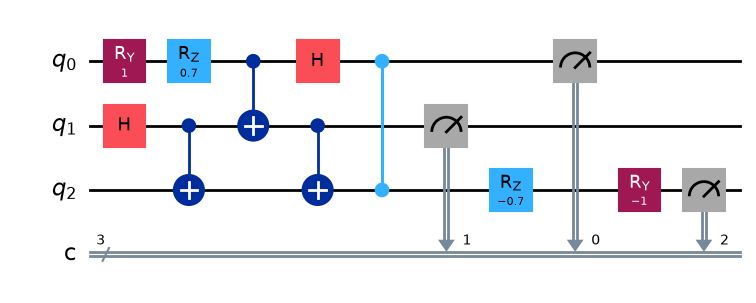

In [2]:
def teleport_circuit():
    """Teleport the state of qubit 0 to qubit 2 using an entangled pair (1,2)."""
    qc = QuantumCircuit(3, 3)
    # Prepare a state to send on qubit 0. It's a "generic" state on purpose:
    # if either correction below is missing, the check in the next cell catches it.
    qc.ry(1.0, 0)
    qc.rz(0.7, 0)

    # Entangle qubits 1 and 2 (create Bell pair)
    qc.h(1)
    qc.cx(1, 2)

    # Bell measurement basis on qubits 0 and 1
    qc.cx(0, 1)
    qc.h(0)

    # Corrections (deferred measurement: cx and cz)
    qc.cx(1, 2)
    qc.cz(0, 2)

    # Undo Alice's preparation on qubit 2 (inverse gates, reverse order): a working link leaves |0>
    qc.rz(-0.7, 2)
    qc.ry(-1.0, 2)

    # Measure all 3 qubits
    qc.measure([0, 1, 2], [0, 1, 2])
    return qc

qc = teleport_circuit()
qc.draw("mpl")

In [3]:
# Run and show it works
counts = sim.run(transpile(qc, sim), shots=1024).result().get_counts()
print(counts)

# Qiskit prints bits as (qubit 2)(qubit 1)(qubit 0). Qubits 0 and 1 are random.
# Undoing the state Alice sent turns qubit 2 back into |0>, so if the link works, it reads 0 on every shot.
zeros = sum(c for bits, c in counts.items() if bits[0] == "0")
print(f"qubit 2 read 0 on {zeros} of {sum(counts.values())} shots (all of them means the link works)")

{'001': 232, '011': 278, '000': 292, '010': 222}
qubit 2 read 0 on 1024 of 1024 shots (all of them means the link works)


In [4]:
# Run the same link through qBraid on IonQ's free simulator
from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

device = QbraidProvider().get_device("ionq:ionq:sim:simulator")
job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})
print("Job ID:", job.id)          # copy this into your write-up
ionq_counts = job.result().data.get_counts()
zeros = sum(c for bits, c in ionq_counts.items() if bits[0] == "0")
print(f"qubit 2 read 0 on {zeros} of {sum(ionq_counts.values())} shots (close to all means the link works)")
# qBraid may warn that measurements are ignored: IonQ measures every qubit at the end, and the
# cx/cz corrections still work because they are applied as quantum gates.


Job ID: ionq:ionq:sim:simulator-a7ae-qjob-6af8baa7c8f5265fb3f203fa


qubit 2 read 0 on 195 of 200 shots (close to all means the link works)


### Real hardware: the same link on Rigetti Cepheus

The same teleportation circuit on a real quantum computer (Rigetti Cepheus, 38.5 credits for 200 shots), and on Quantinuum's free H2 emulator for comparison. The three qubits sit on one chip, so this tests the link's logic on real, noisy gates, not its distance.

In [5]:
runs = {
    "Rigetti Cepheus (real QPU)": "aws:rigetti:qpu:cepheus-1-108q",
    "Quantinuum H2 emulator (emulator, not hardware)": "quantinuum:quantinuum:sim:h2-emulator",
}
provider = QbraidProvider()
hw_jobs = {name: provider.get_device(d).run(qc, shots=200) for name, d in runs.items()}   # send both, then collect
for name, j in hw_jobs.items():
    c = j.result().data.get_counts()
    z = sum(v for bits, v in c.items() if bits[0] == "0")
    print(f"{name}: job {j.id}")
    print(f"  qubit 2 read 0 on {z} of {sum(c.values())} shots")

Rigetti Cepheus (real QPU): job aws:rigetti:qpu:cepheus-1-108q-a7ae-qjob-6af8bab8c8f5265fb3f2040a
  qubit 2 read 0 on 167 of 200 shots


Quantinuum H2 emulator (emulator, not hardware): job quantinuum:quantinuum:sim:h2-emulator-a7ae-qjob-6af8babac8f5265fb3f2040d
  qubit 2 read 0 on 199 of 200 shots


## Results

Qubit 2 read 0, meaning the link worked, on 1024 of 1024 shots on Qiskit Aer, 195 of 200 on IonQ's noisy simulator, 199 of 200 on the Quantinuum H2 emulator, and 167 of 200 (83.5%) on Rigetti Cepheus, a real QPU. Parts 1, 2, 4 and 5 (architecture, assumptions and tradeoffs, rollout plan, cost versus security) are in `WRITEUP.md`, Step 3.